# Malnutrition detection 

In [1]:
!pip install matplotlib seaborn


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# import tensorflow as tf


In [3]:
malnutrition = pd.read_csv('Malnutrition data.csv')

In [4]:
df = malnutrition

In [5]:
malnutrition.head()

,Sex,Age,Height,Weight,Low Income,Lower Middle Income,Upper Middle Income,Status
0,1,5,75,17,1,0,0,Stunting
1,0,4,101,13,1,0,0,Stunting
2,0,4,71,17,1,0,0,Stunting
3,0,3,81,13,0,0,1,Stunting
4,0,1,79,16,0,0,1,Stunting


In [6]:
# Checking the number of entries and any missing values

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 837 entries, 0 to 836
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sex                  837 non-null    int64
 1   Age                  837 non-null    int64
 2   Height               837 non-null    int64
 3   Weight               837 non-null    int64
 4   Low Income           837 non-null    int64
 5   Lower Middle Income  837 non-null    int64
 6   Upper Middle Income  837 non-null    int64
 7   Status               837 non-null    str  
dtypes: int64(7), str(1)
memory usage: 52.4 KB


In [8]:
# Dealing with categorical data

In [9]:
df['Sex'].value_counts()

Sex
1    421
0    416
Name: count, dtype: int64

In [10]:
df['Status'].value_counts()

Status
Stunting       696
Overweight      94
Underweight     43
Wasting          4
Name: count, dtype: int64

In [11]:
df.describe()

,Sex,Age,Height,Weight,Low Income,Lower Middle Income,Upper Middle Income
count,837.000000,837.000000,837.000000,837.000000,837.000000,837.000000,837.000000
mean,0.502987,2.947431,88.559140,14.463560,0.227001,0.397849,0.291517
std,0.500290,1.406447,10.821536,3.457559,0.419144,0.489747,0.454733
min,0.000000,1.000000,70.000000,9.000000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,80.000000,11.000000,0.000000,0.000000,0.000000
50%,1.000000,3.000000,89.000000,15.000000,0.000000,0.000000,0.000000
75%,1.000000,4.000000,98.000000,17.000000,0.000000,1.000000,1.000000
max,1.000000,5.000000,107.000000,20.000000,1.000000,1.000000,1.000000


array([[<Axes: title={'center': 'Sex'}>, <Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Height'}>],
       [<Axes: title={'center': 'Weight'}>,
        <Axes: title={'center': 'Low Income'}>,
        <Axes: title={'center': 'Lower Middle Income'}>],
       [<Axes: title={'center': 'Upper Middle Income'}>, <Axes: >,
        <Axes: >]], dtype=object)

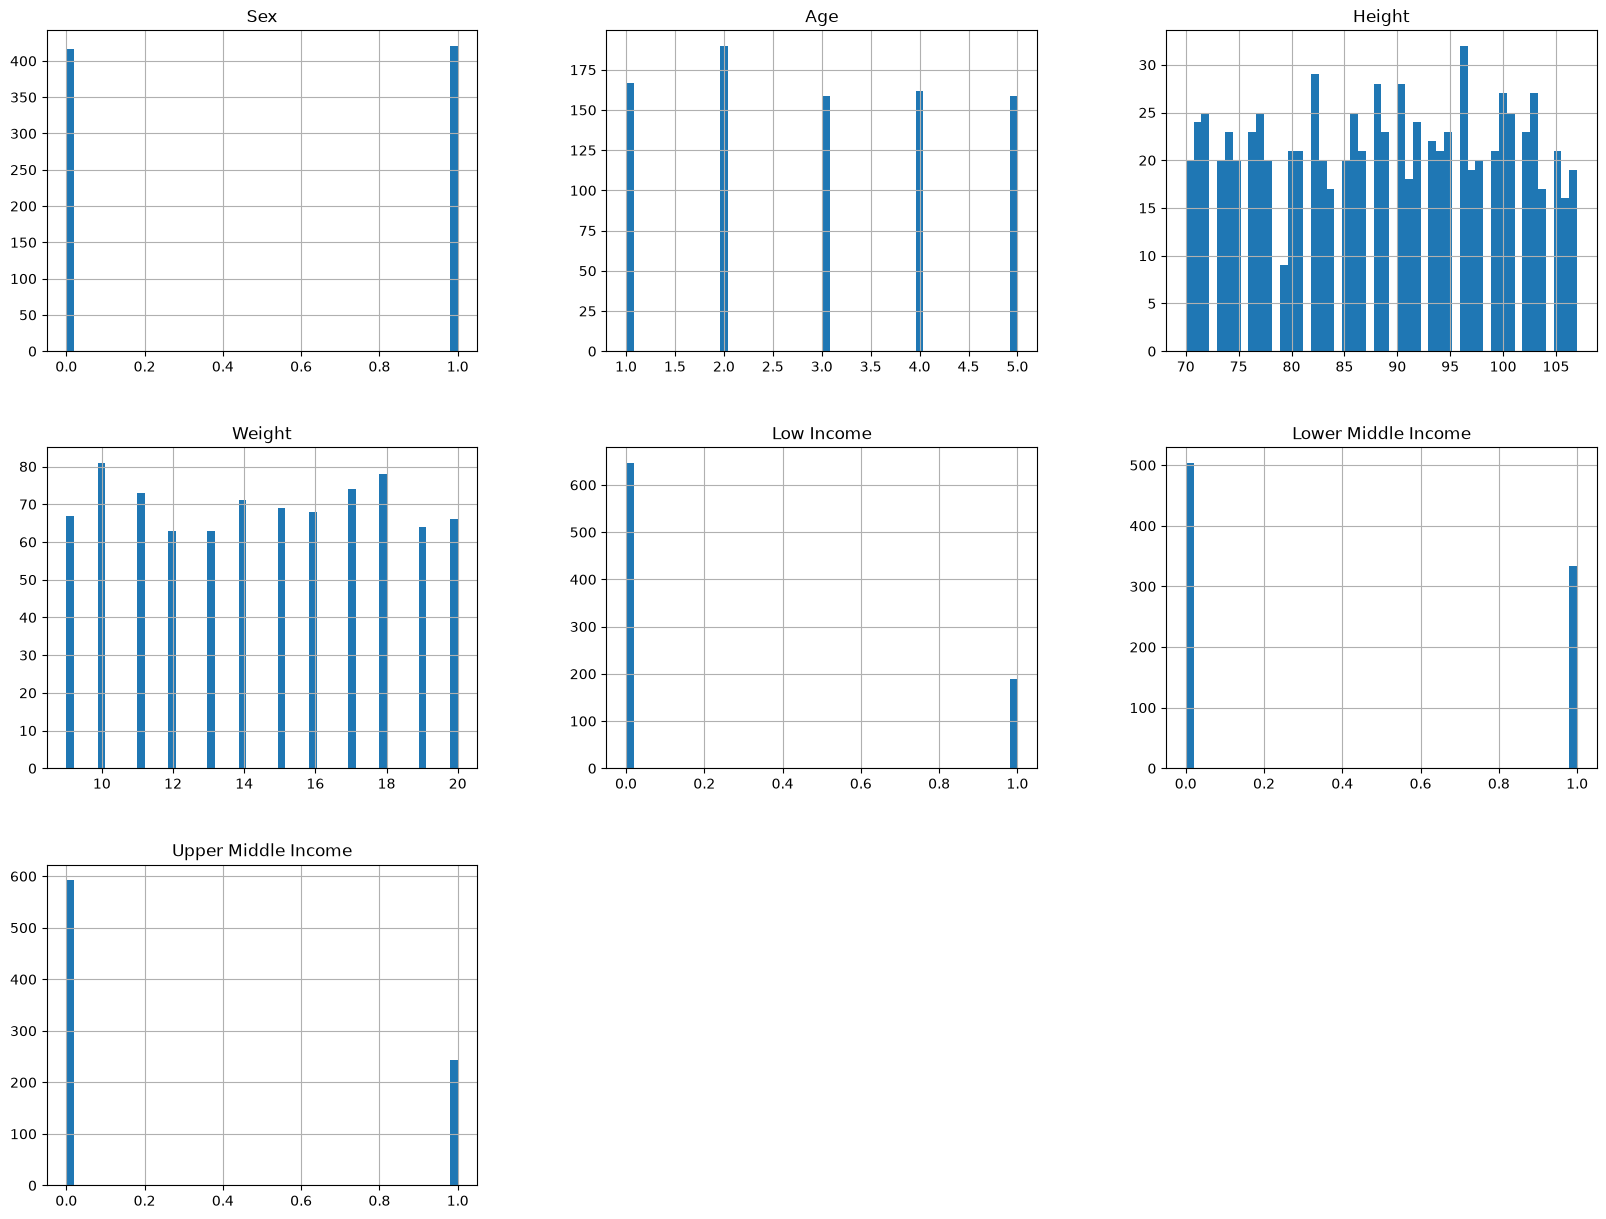

In [12]:
df.hist(bins=50, figsize=(20,15))

In [13]:
# Visualising informaiton about the Status column which is categorical data

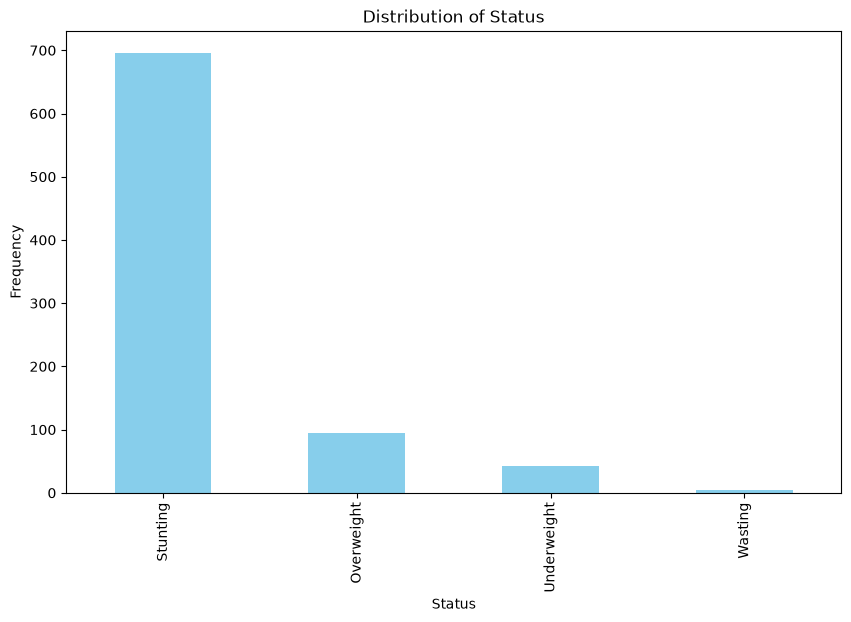

In [14]:
df['Status'].value_counts().plot(kind='bar', figsize=(10, 6), color='skyblue')

plt.title('Distribution of Status')
plt.xlabel('Status')
plt.ylabel('Frequency')
plt.show()

In [15]:
print(df.columns)

Index(['Sex', 'Age', 'Height', 'Weight', 'Low Income', 'Lower Middle Income',
       'Upper Middle Income', 'Status'],
      dtype='str')


In [16]:
# Removing the unwanted columns as seen below:

In [17]:
df = df.drop('Low Income '.strip(), axis=1)
df = df.drop('Lower Middle Income '.strip(), axis=1)
df = df.drop('Upper Middle Income '.strip(), axis=1)

In [18]:
df.describe()

,Sex,Age,Height,Weight
count,837.000000,837.000000,837.000000,837.000000
mean,0.502987,2.947431,88.559140,14.463560
std,0.500290,1.406447,10.821536,3.457559
min,0.000000,1.000000,70.000000,9.000000
25%,0.000000,2.000000,80.000000,11.000000
50%,1.000000,3.000000,89.000000,15.000000
75%,1.000000,4.000000,98.000000,17.000000
max,1.000000,5.000000,107.000000,20.000000


In [19]:
# Separating the labels and features

In [20]:
X = df.drop("Status", axis=1)  # Features
y = df["Status"]  # Labels

# X = df.iloc[:, :4]
# y = df.iloc[:, 4]

In [21]:
# Visualising the interger type data using a histogram

array([[<Axes: title={'center': 'Sex'}>, <Axes: title={'center': 'Age'}>],
       [<Axes: title={'center': 'Height'}>,
        <Axes: title={'center': 'Weight'}>]], dtype=object)

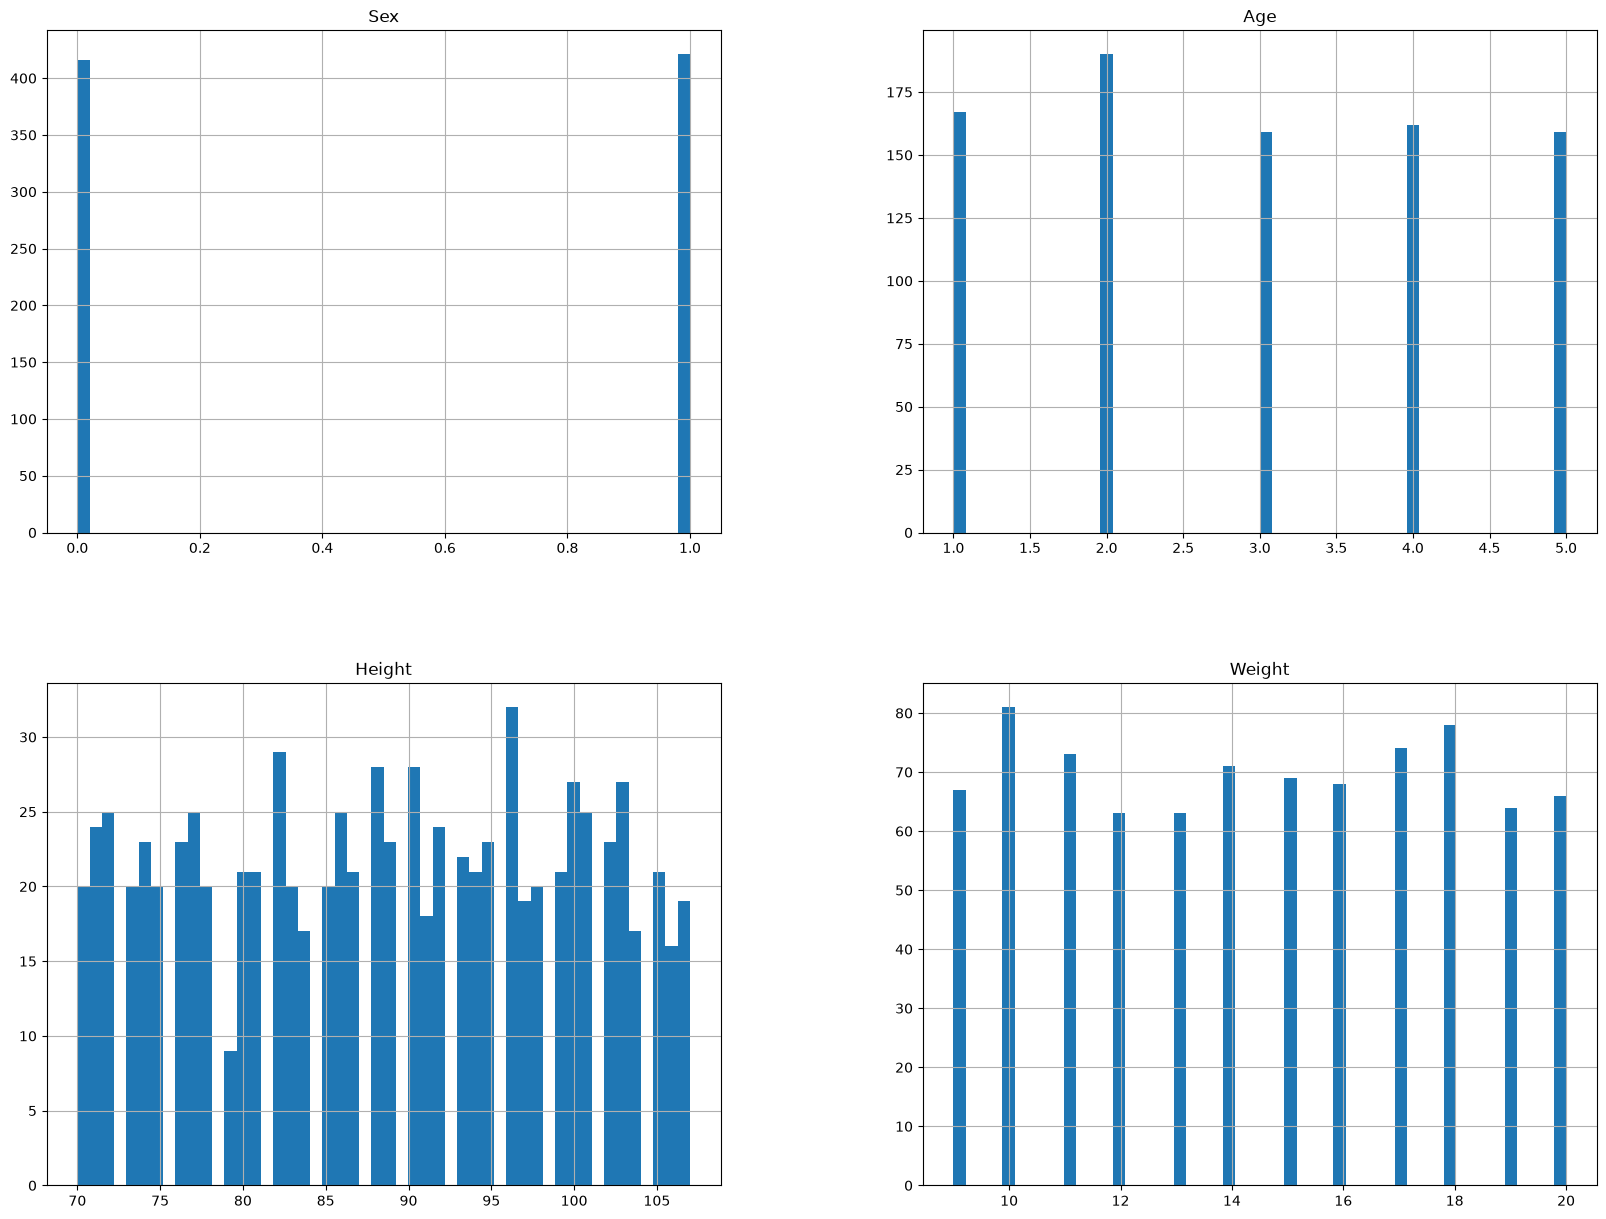

In [22]:
df.hist(bins=50, figsize=(20,15))

In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 837 entries, 0 to 836
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Sex     837 non-null    int64
 1   Age     837 non-null    int64
 2   Height  837 non-null    int64
 3   Weight  837 non-null    int64
 4   Status  837 non-null    str  
dtypes: int64(4), str(1)
memory usage: 32.8 KB


In [24]:
# df_plot = pd.concat([X, y], axis=1)

# # Create a box plot
# plt.figure(figsize=(12, 8))
# sns.boxplot(data=df_plot, x='Status', y='Height') 
# plt.title('Box Plot of Age by Status')
# plt.show()

In [25]:
# df_plot = pd.concat([X, y], axis=1)

# # Create box plots for all features
# plt.figure(figsize=(16, 10))
# sns.boxplot(data=df_plot.drop('Status', axis=1))
# plt.title('Box Plots of Features by Status')
# plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for better readability
# plt.show()

In [26]:
## Splitting the dataset into training, validation and testing

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [28]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)

# Split the 'temp' sets into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Print the shapes of the resulting sets
print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Testing set:", X_test.shape, y_test.shape)

Training set: (585, 4) (585,)
Validation set: (126, 4) (126,)
Testing set: (126, 4) (126,)


In [29]:
# from sklearn.ensemble import RandomForestClassifier
# model = RandomForestClassifier(n_estimators=300)
# model.fit(X_train, y_train)

In [30]:
# predict = model.predict(X_temp)
# predict

In [31]:
# from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
# print(confusion_matrix(y_temp, predict))
# print(classification_report(y_temp, predict))
# print("Accuracy Of Our Model Is:-",accuracy_score(y_temp, predict)*100, "%")

In [32]:
# rf_classifier = RandomForestClassifier(random_state=42)

# # Train the classifier on the training set
# rf_classifier.fit(X_train, y_train)

# # Make predictions on the validation set
# y_val_pred = rf_classifier.predict(X_val)

# # Evaluate the accuracy on the validation set
# val_accuracy = accuracy_score(y_val, y_val_pred)*100
# print(f'Validation Accuracy: {val_accuracy:.2f}')

# # Make predictions on the test set
# y_test_pred = rf_classifier.predict(X_test)

# # Evaluate the accuracy on the test set
# test_accuracy = accuracy_score(y_test, y_test_pred)*100
# print(f'Test Accuracy: {test_accuracy:.2f}')

In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# Train the model on the training set
model = RandomForestClassifier(n_estimators=300)
model.fit(X_train, y_train)

# Predictions on the validation set
y_val_pred = model.predict(X_val)

# Evaluate the model on the validation set
print("Validation Set:")
print(confusion_matrix(y_val, y_val_pred))
print(classification_report(y_val, y_val_pred))
print("Accuracy: {:.2f}%".format(accuracy_score(y_val, y_val_pred) * 100))

# Predictions on the temporary set
y_temp_pred = model.predict(X_temp)

# Evaluate the model on the temporary set
print("\nTemporary Set:")
print(confusion_matrix(y_temp, y_temp_pred))
print(classification_report(y_temp, y_temp_pred))
print("Accuracy: {:.2f}%".format(accuracy_score(y_temp, y_temp_pred) * 100))


Validation Set:
[[  2   8   0   0]
 [  4 104   2   0]
 [  1   4   0   0]
 [  0   1   0   0]]
              precision    recall  f1-score   support

  Overweight       0.29      0.20      0.24        10
    Stunting       0.89      0.95      0.92       110
 Underweight       0.00      0.00      0.00         5
     Wasting       0.00      0.00      0.00         1

    accuracy                           0.84       126
   macro avg       0.29      0.29      0.29       126
weighted avg       0.80      0.84      0.82       126

Accuracy: 84.13%

Temporary Set:
[[  2  25   1   0]
 [  9 196   6   0]
 [  2  10   0   0]
 [  0   1   0   0]]
              precision    recall  f1-score   support

  Overweight       0.15      0.07      0.10        28
    Stunting       0.84      0.93      0.88       211
 Underweight       0.00      0.00      0.00        12
     Wasting       0.00      0.00      0.00         1

    accuracy                           0.79       252
   macro avg       0.25      0.25   

C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [34]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# Train the model on the training set
model = RandomForestClassifier(n_estimators=300)
model.fit(X_train, y_train)

# Predictions on the validation set
y_val_pred = model.predict(X_val)

# Print the predicted labels and compare with the actual labels
print("Predicted Labels:", y_val_pred)
print("Actual Labels   :", y_val.tolist())  # Convert y_val to a list for easy comparison

# Evaluate the model on the validation set
print("Validation Set:")
print(confusion_matrix(y_val, y_val_pred))
print(classification_report(y_val, y_val_pred))
print("Accuracy: {:.2f}%".format(accuracy_score(y_val, y_val_pred) * 100))


Predicted Labels: ['Stunting' 'Stunting' 'Overweight' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Overweight' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Underweight' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Overweight' 'Overweight'
 'Stunting' 'Stunting' 'Stunting' 'Underweight' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Overweight'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Underweight' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Underweight'
 'Stunting' 'Stunting'

C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# Train the model on the training set
model = RandomForestClassifier(n_estimators=300)
model.fit(X_train, y_train)

# Predictions on the test set
y_test_pred = model.predict(X_test)

# Print the predicted labels and compare with the actual labels
print("Predicted Labels (Test Set):", y_test_pred)
print("Actual Labels (Test Set)   :", y_test.tolist())  # Convert y_test to a list for easy comparison

# Evaluate the model on the test set
print("\nTest Set:")
print(confusion_matrix(y_test, y_test_pred))
print(classification_report(y_test, y_test_pred))
print("Accuracy: {:.2f}%".format(accuracy_score(y_test, y_test_pred) * 100))




Predicted Labels (Test Set): ['Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Overweight' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Overweight' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Overweight' 'Stunting' 'Underweight'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Underweight'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Overweight' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Underweight' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Overweight' 'Stunting' 'Stunting'
 'Stunting' 'S

In [36]:
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.model_selection import train_test_split

# Assuming X contains your features and y contains your labels
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)

# Split the 'temp' sets into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Create an SVM model
svm_model = SVC(kernel='linear', random_state=42)  # You can adjust the kernel and other parameters based on your data

# Train the SVM model on the training set
svm_model.fit(X_train, y_train)

# Predictions on the validation set
y_val_pred = svm_model.predict(X_val)

# Evaluate the SVM model on the validation set
print("Validation Set:")
print(confusion_matrix(y_val, y_val_pred))
print(classification_report(y_val, y_val_pred))
print("Accuracy: {:.2f}%".format(accuracy_score(y_val, y_val_pred) * 100))

# Predictions on the test set
y_test_pred = svm_model.predict(X_test)

# Evaluate the SVM model on the test set
print("\nTest Set:")
print(confusion_matrix(y_test, y_test_pred))
print(classification_report(y_test, y_test_pred))
print("Accuracy: {:.2f}%".format(accuracy_score(y_test, y_test_pred) * 100))


Validation Set:
[[  0  10   0   0]
 [  0 110   0   0]
 [  0   5   0   0]
 [  0   1   0   0]]
              precision    recall  f1-score   support

  Overweight       0.00      0.00      0.00        10
    Stunting       0.87      1.00      0.93       110
 Underweight       0.00      0.00      0.00         5
     Wasting       0.00      0.00      0.00         1

    accuracy                           0.87       126
   macro avg       0.22      0.25      0.23       126
weighted avg       0.76      0.87      0.81       126

Accuracy: 87.30%

Test Set:
[[  0  18   0]
 [  0 101   0]
 [  0   7   0]]
              precision    recall  f1-score   support

  Overweight       0.00      0.00      0.00        18
    Stunting       0.80      1.00      0.89       101
 Underweight       0.00      0.00      0.00         7

    accuracy                           0.80       126
   macro avg       0.27      0.33      0.30       126
weighted avg       0.64      0.80      0.71       126

Accuracy: 80.16%


C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [37]:
# Below, I used neural networks

In [38]:
# import matplotlib.pyplot as plt

# # Plot training & validation accuracy values
# plt.plot(history.history['accuracy'])
# plt.plot(history.history['val_accuracy'])
# plt.title('Model accuracy')
# plt.xlabel('Epoch')
# plt.ylabel('Accuracy')
# plt.legend(['Train', 'Validation'], loc='upper left')
# plt.show()

# # Plot training & validation loss values
# plt.plot(history.history['loss'])
# plt.plot(history.history['val_loss'])
# plt.title('Model loss')
# plt.xlabel('Epoch')
# plt.ylabel('Loss')
# plt.legend(['Train', 'Validation'], loc='upper left')
# plt.show()


In [39]:
# In the code below, I encoded the non-numeric label to numeric and used the SVM algorithm 

In [40]:
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Assuming X contains your features and y contains your labels
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)

# Split the 'temp' sets into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Encode non-numeric labels in y_train using LabelEncoder
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)

# Create an SVM model
svm_model = SVC(kernel='linear', random_state=42)

# Train the SVM model on the training set
svm_model.fit(X_train, y_train_encoded)

# Encode non-numeric labels in y_val and y_test
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

# Predictions on the validation set
y_val_pred = svm_model.predict(X_val)

# Evaluate the SVM model on the validation set
print("Validation Set:")
print(confusion_matrix(y_val_encoded, y_val_pred))
print(classification_report(y_val_encoded, y_val_pred))
print("Accuracy: {:.2f}%".format(accuracy_score(y_val_encoded, y_val_pred) * 100))

# Predictions on the test set
y_test_pred = svm_model.predict(X_test)

# Evaluate the SVM model on the test set
print("\nTest Set:")
print(confusion_matrix(y_test_encoded, y_test_pred))
print(classification_report(y_test_encoded, y_test_pred))
print("Accuracy: {:.2f}%".format(accuracy_score(y_test_encoded, y_test_pred) * 100))



Validation Set:
[[  0  10   0   0]
 [  0 110   0   0]
 [  0   5   0   0]
 [  0   1   0   0]]
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        10
           1       0.87      1.00      0.93       110
           2       0.00      0.00      0.00         5
           3       0.00      0.00      0.00         1

    accuracy                           0.87       126
   macro avg       0.22      0.25      0.23       126
weighted avg       0.76      0.87      0.81       126

Accuracy: 87.30%

Test Set:
[[  0  18   0]
 [  0 101   0]
 [  0   7   0]]
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        18
           1       0.80      1.00      0.89       101
           2       0.00      0.00      0.00         7

    accuracy                           0.80       126
   macro avg       0.27      0.33      0.30       126
weighted avg       0.64      0.80      0.71       126

Accuracy: 80.16%


C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [41]:
# Below, I encoded the non numeric labels to numeric and used Random Forest Classifier

In [42]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder

# Assuming 'status' is the column to be encoded in your dataset
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)
y_val_encoded = label_encoder.transform(y_val)  # Assuming you have a validation set 'y_val'

# Train the model on the training set
model = RandomForestClassifier(n_estimators=300)
model.fit(X_train, y_train_encoded)

# Predictions on the test set
y_test_pred_encoded = model.predict(X_test)
y_val_pred_encoded = model.predict(X_val)  # Assuming you have a validation set 'X_val'

# Decode the predicted labels back to original status labels
y_test_pred = label_encoder.inverse_transform(y_test_pred_encoded)
y_val_pred = label_encoder.inverse_transform(y_val_pred_encoded)

# Print the predicted labels and compare with the actual labels for both test and validation sets
print("Test Set:")
print("Predicted Labels (Test Set):", y_test_pred)
print("Actual Labels (Test Set)   :", y_test.tolist())  # Convert y_test to a list for easy comparison
print("\nValidation Set:")
print("Predicted Labels (Validation Set):", y_val_pred)
print("Actual Labels (Validation Set)   :", y_val.tolist())  # Convert y_val to a list for easy comparison

# Evaluate the model on the test set
print("\nTest Set:")
print(confusion_matrix(y_test, y_test_pred))
print(classification_report(y_test, y_test_pred))
print("Accuracy: {:.2f}%".format(accuracy_score(y_test, y_test_pred) * 100))

# Evaluate the model on the validation set
print("\nValidation Set:")
print(confusion_matrix(y_val, y_val_pred))
print(classification_report(y_val, y_val_pred))
print("Accuracy: {:.2f}%".format(accuracy_score(y_val, y_val_pred) * 100))


Test Set:
Predicted Labels (Test Set): ['Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Overweight' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Overweight' 'Stunting' 'Underweight'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Underweight'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Overweight' 'Stunting' 'Stunting' 'Underweight' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting' 'Stunting'
 'Stunti

C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [43]:
## Checking the matching of the numeric values and there corresponding actual label values

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Assuming 'status' is the column to be encoded in your dataset
label_encoder = LabelEncoder()

# Create a sample DataFrame with your data
# Replace this with your actual dataset
data = {'status': ['Stunting', 'Overweight', 'Underweight', 'Wasting', 'Stunting']}
df = pd.DataFrame(data)

# Fit and transform the LabelEncoder on the original label column
encoded_labels = label_encoder.fit_transform(df['status'])

# Print the mapping between encoded values and original labels
print("Encoded Labels:")
for label, encoded_value in zip(label_encoder.classes_, range(len(label_encoder.classes_))):
    print(f"Encoded Value: {encoded_value} -> Original Label: {label}")


Encoded Labels:
Encoded Value: 0 -> Original Label: Overweight
Encoded Value: 1 -> Original Label: Stunting
Encoded Value: 2 -> Original Label: Underweight
Encoded Value: 3 -> Original Label: Wasting


In [45]:
## Trying out SMOTE

In [46]:
# pip install -U imbalanced-learn

In [47]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split


# Split the dataset into training, validation, and test sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)

# Split the 'temp' sets into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Print the shapes of the resulting sets
print("Before SMOTE - Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Testing set:", X_test.shape, y_test.shape)

# Check the number of samples in the minority class
min_class_samples = min(y_train.value_counts())

# Apply SMOTE only to the training set with k_neighbors
k_neighbors = min(6, min_class_samples - 1)  # Ensure k_neighbors is less than min_class_samples
smote = SMOTE(random_state=42, k_neighbors=k_neighbors)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Print the shapes of the resampled training set
print("\nAfter SMOTE - Resampled Training set:", X_train_resampled.shape, y_train_resampled.shape)





Before SMOTE - Training set: (585, 4) (585,)
Validation set: (126, 4) (126,)
Testing set: (126, 4) (126,)

After SMOTE - Resampled Training set: (1940, 4) (1940,)


In [48]:
# Print the distribution of the target variable before and after SMOTE
print("Before SMOTE - Training set:")
print(y_train.value_counts())

# Print the distribution of the target variable after SMOTE
print("\nAfter SMOTE - Resampled Training set:")
print(y_train_resampled.value_counts())

# Print the distribution of the target variable in the validation set
print("\nValidation set:")
print(y_val.value_counts())

# Print the distribution of the target variable in the testing set
print("\nTesting set:")
print(y_test.value_counts())


Before SMOTE - Training set:
Status
Stunting       485
Overweight      66
Underweight     31
Wasting          3
Name: count, dtype: int64

After SMOTE - Resampled Training set:
Status
Stunting       485
Overweight     485
Underweight    485
Wasting        485
Name: count, dtype: int64

Validation set:
Status
Stunting       110
Overweight      10
Underweight      5
Wasting          1
Name: count, dtype: int64

Testing set:
Status
Stunting       101
Overweight      18
Underweight      7
Name: count, dtype: int64


In [49]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Split the dataset into training, validation, and test sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)

# Split the 'temp' sets into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Print the shapes of the resulting sets
print("Before SMOTE - Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Testing set:", X_test.shape, y_test.shape)

# Check the number of samples in the minority class
min_class_samples = min(y_train.value_counts())

# Apply SMOTE only to the training set with k_neighbors
k_neighbors = min(6, min_class_samples - 1)  # Ensure k_neighbors is less than min_class_samples
smote = SMOTE(random_state=42, k_neighbors=k_neighbors)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Safe drop (ignores if columns were already removed)
columns_to_remove = ["Low Income", "Lower Middle Income", "Upper Middle Income"]
X_train_resampled = X_train_resampled.drop(columns=columns_to_remove, errors='ignore')
X_val = X_val.drop(columns=columns_to_remove, errors='ignore')
X_test = X_test.drop(columns=columns_to_remove, errors='ignore')

# Print the shapes of the resampled training set
print("\nAfter SMOTE - Resampled Training set:", X_train_resampled.shape, y_train_resampled.shape)

# Continue with your modeling and evaluation steps



Before SMOTE - Training set: (585, 4) (585,)
Validation set: (126, 4) (126,)
Testing set: (126, 4) (126,)

After SMOTE - Resampled Training set: (1940, 4) (1940,)


In [50]:
# List of columns to be removed
columns_to_remove = ["Low Income", "Lower Middle Income", "Upper Middle Income"]

# Remove the specified columns from the DataFrame
X_train_resampled_filtered = X_train_resampled.drop(columns=columns_to_remove, errors='ignore')

# Display the resulting DataFrame
print(X_train_resampled_filtered.head())


   Sex  Age  Height  Weight
0    1    5      82      10
1    0    5      82      16
2    1    3     104      10
3    0    5      70      18
4    1    1      91      20


In [51]:
# Display the first few rows of the feature DataFrame
print("Features after removing columns:")
print(X_train_resampled.head())

# Display the column names
print("\nFeature column names after removing columns:")
print(X_train_resampled.columns)

# Display the target variable
print("\nLabels in the training set:")
print(y_train_resampled.head())

Features after removing columns:
   Sex  Age  Height  Weight
0    1    5      82      10
1    0    5      82      16
2    1    3     104      10
3    0    5      70      18
4    1    1      91      20

Feature column names after removing columns:
Index(['Sex', 'Age', 'Height', 'Weight'], dtype='str')

Labels in the training set:
0    Stunting
1    Stunting
2    Stunting
3    Stunting
4    Stunting
Name: Status, dtype: str


In [52]:
y_train_resampled_encoded = label_encoder.fit_transform(y_train_resampled)


In [53]:
# Removing unwanted features from the dataset

In [54]:
# import pandas as pd

# # Assuming your original dataset is df
# # List of columns to be removed
# columns_to_remove = ["Low Income", "Lower Middle Income", "Upper Middle Income"]

# # Create a new DataFrame with the specified columns removed
# df_filtered = df.drop(columns=columns_to_remove, axis=1)

# # Display the resulting DataFrame
# print(df_filtered.head())




In [55]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Encode labels if they are text ('Stunting', 'Wasting', etc.)
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train_resampled)
y_test_encoded = le.transform(y_test)

# 2. Train the Random Forest Model
model = RandomForestClassifier(n_estimators=300, random_state=42)
model.fit(X_train_resampled, y_train_encoded)

# 3. Predict on the test set
y_pred_encoded = model.predict(X_test)
y_pred = le.inverse_transform(y_pred_encoded)

# 4. Print Empirical Metrics
print("================= TEST EVALUATION =================")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

================= TEST EVALUATION =================
Overall Accuracy: 57.14%

Classification Report:
              precision    recall  f1-score   support

  Overweight       0.15      0.22      0.18        18
    Stunting       0.77      0.67      0.72       101
 Underweight       0.00      0.00      0.00         7

    accuracy                           0.57       126
   macro avg       0.31      0.30      0.30       126
weighted avg       0.64      0.57      0.60       126

Confusion Matrix:
[[ 4 14  0]
 [21 68 12]
 [ 1  6  0]]


In [56]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("================= TEST EVALUATION =================")
# If your true test labels are encoded, use y_test_encoded, otherwise y_test
try:
    print(f"Accuracy: {accuracy_score(y_test, y_test_pred) * 100:.2f}%\n")
    print("Classification Report:")
    print(classification_report(y_test, y_test_pred))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_test_pred))
except Exception:
    # Fallback if y_test is still numerically encoded
    print(f"Accuracy: {accuracy_score(y_test_encoded, y_test_pred_encoded) * 100:.2f}%\n")
    print("Classification Report:")
    print(classification_report(y_test_encoded, y_test_pred_encoded))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test_encoded, y_test_pred_encoded))

================= TEST EVALUATION =================
Accuracy: 73.02%

Classification Report:
              precision    recall  f1-score   support

  Overweight       0.00      0.00      0.00        18
    Stunting       0.80      0.91      0.85       101
 Underweight       0.00      0.00      0.00         7

    accuracy                           0.73       126
   macro avg       0.27      0.30      0.28       126
weighted avg       0.64      0.73      0.68       126

Confusion Matrix:
[[ 0 17  1]
 [ 4 92  5]
 [ 1  6  0]]


In [57]:
!pip install scikit-learn pandas numpy imbalanced-learn joblib


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


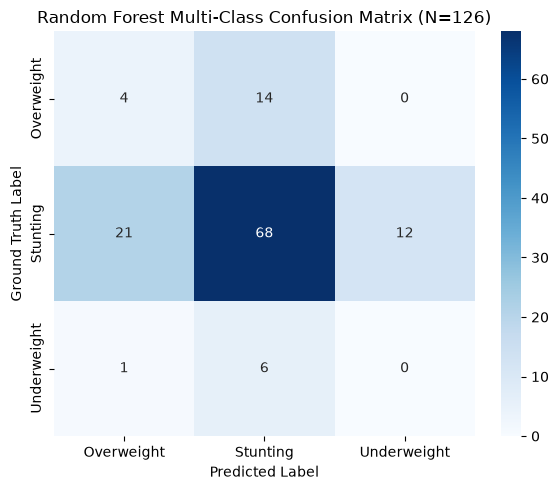

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Re-plot confusion matrix cleanly
cm = confusion_matrix(y_test, y_pred)
labels = ['Overweight', 'Stunting', 'Underweight']

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=labels, yticklabels=labels)
plt.title('Random Forest Multi-Class Confusion Matrix (N=126)')
plt.xlabel('Predicted Label')
plt.ylabel('Ground Truth Label')
plt.tight_layout()
plt.savefig('confusion_matrix_rf.png', dpi=300)
plt.show()

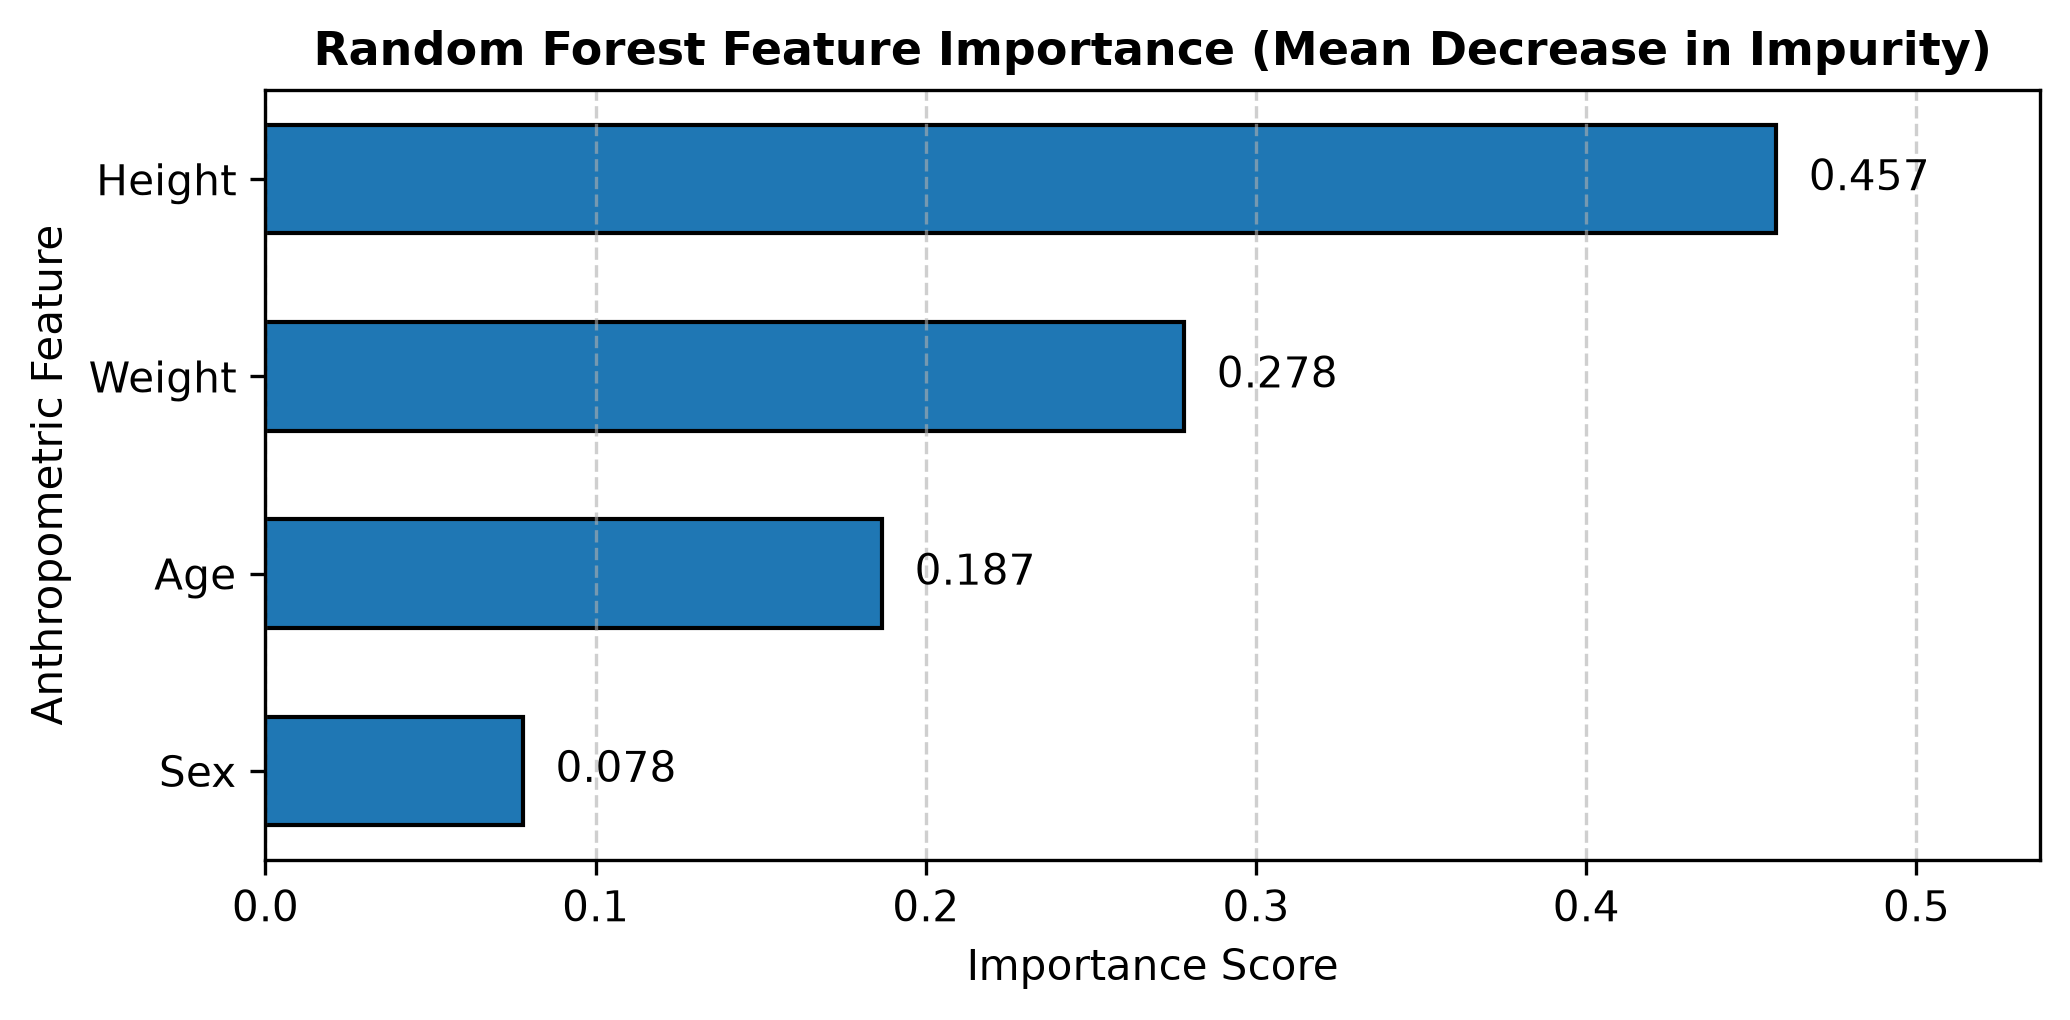

In [59]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Extract feature importances from your trained Random Forest model
feature_names = ['Sex', 'Age', 'Height', 'Weight']
importances = model.feature_importances_

# 2. Create a clean DataFrame and sort descending
feat_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

# 3. Plot horizontal bar chart
plt.figure(figsize=(7, 3.5), dpi=300)
bars = plt.barh(feat_df['Feature'], feat_df['Importance'], color='#1f77b4', edgecolor='black', height=0.55)

# Add numerical values to the end of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, 
             f'{width:.3f}', ha='left', va='center', fontsize=10)

plt.xlim(0, max(importances) + 0.08)
plt.title('Random Forest Feature Importance (Mean Decrease in Impurity)', fontsize=11, fontweight='bold')
plt.xlabel('Importance Score', fontsize=10)
plt.ylabel('Anthropometric Feature', fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()

# 4. Save figure directly for your IEEE document
plt.savefig('rf_feature_importance.png', dpi=300)
plt.show()

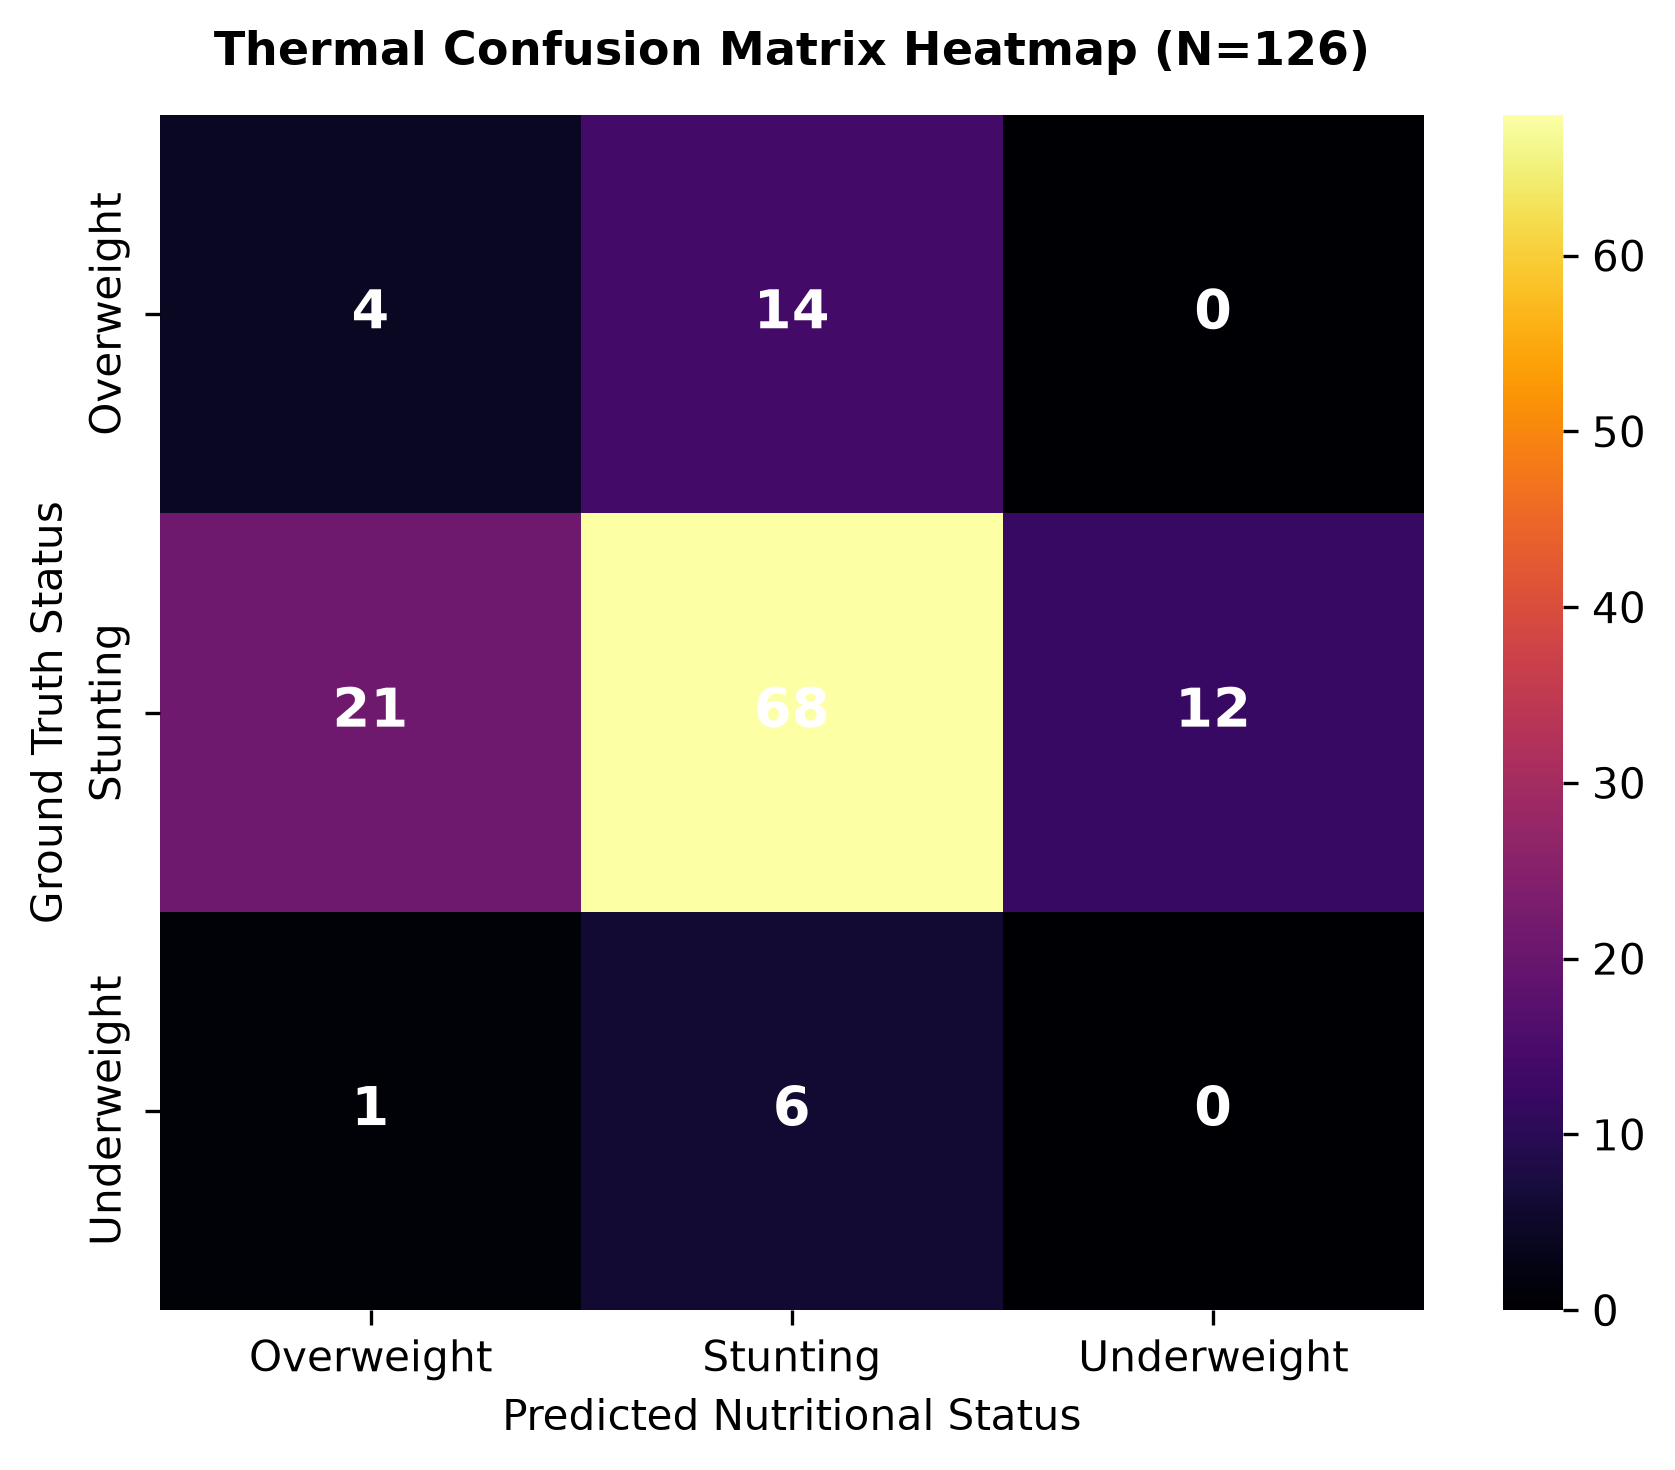

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
labels = ['Overweight', 'Stunting', 'Underweight']

plt.figure(figsize=(6, 5), dpi=300)
sns.heatmap(cm, annot=True, fmt='d', cmap='inferno', 
            xticklabels=labels, yticklabels=labels,
            cbar=True, annot_kws={"size": 13, "weight": "bold", "color": "white"})

plt.title('Thermal Confusion Matrix Heatmap (N=126)', fontsize=11, fontweight='bold', pad=12)
plt.xlabel('Predicted Nutritional Status', fontsize=10)
plt.ylabel('Ground Truth Status', fontsize=10)
plt.tight_layout()
plt.savefig('thermal_confusion_matrix.png', dpi=300)
plt.show()

In [61]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [62]:
import os
print([f for f in os.listdir('.') if f.endswith('.csv')])

['Malnutrition data.csv', 'resampled_data.csv', 'Xtrain.csv']


In [63]:
import numpy as np
import pandas as pd
import joblib
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# 0. Load the dataset directly using the correct filename
df = pd.read_csv('Malnutrition data.csv')

# Prune non-anthropometric income columns if present
drop_cols = [c for c in ['Income', 'Family_Income', 'Income_Level'] if c in df.columns]
if drop_cols:
    df = df.drop(columns=drop_cols)

# Standardize Sex encoding to binary (0 = Female, 1 = Male)
if df['Sex'].dtype == object:
    df['Sex'] = df['Sex'].astype(str).str.strip().str.lower().map({'male': 1, 'm': 1, '1': 1, 'female': 0, 'f': 0, '0': 0})

# 1. Feature Engineering: derive clinical pediatric indices
df_fe = df.copy()
h_m = df_fe['Height'] / 100.0  # Height in meters
df_fe['BMI'] = df_fe['Weight'] / (h_m ** 2)
df_fe['Weight_Height_Ratio'] = df_fe['Weight'] / df_fe['Height']
df_fe['Height_Age_Ratio'] = df_fe['Height'] / df_fe['Age']

feature_cols = ['Sex', 'Age', 'Height', 'Weight', 'BMI', 'Weight_Height_Ratio', 'Height_Age_Ratio']
X = df_fe[feature_cols]
y = df_fe['Status']

# 2. Stratified train-test split (70% train / 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# 3. Target label encoding
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

# 4. Train Modern Gradient Boosted Ensemble (XGBoost)
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.85,
    colsample_bytree=0.85,
    random_state=42,
    eval_metric='mlogloss'
)

xgb_model.fit(X_train, y_train_enc)
preds_enc = xgb_model.predict(X_test)
preds = le.inverse_transform(preds_enc)

# 5. Output Evaluation
test_acc = accuracy_score(y_test, preds)
print(f"=== PROPOSED XGBOOST TEST ACCURACY: {test_acc * 100:.2f}% ===")
print("\nClassification Report:\n", classification_report(y_test, preds))

# 6. Save model artifacts for FastAPI microservice
joblib.dump(xgb_model, 'xgboost_model.joblib')
joblib.dump(le, 'label_encoder.joblib')
print("\n[OK] Saved 'xgboost_model.joblib' and 'label_encoder.joblib' to disk.")

=== PROPOSED XGBOOST TEST ACCURACY: 78.57% ===

Classification Report:
               precision    recall  f1-score   support

  Overweight       0.00      0.00      0.00        28
    Stunting       0.82      0.94      0.88       210
 Underweight       0.00      0.00      0.00        13
     Wasting       0.00      0.00      0.00         1

    accuracy                           0.79       252
   macro avg       0.21      0.24      0.22       252
weighted avg       0.69      0.79      0.73       252


[OK] Saved 'xgboost_model.joblib' and 'label_encoder.joblib' to disk.


C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\rites\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [64]:
import numpy as np
import pandas as pd
import joblib
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from imblearn.over_sampling import SMOTE

# 1. Load dataset
df = pd.read_csv('Malnutrition data.csv')

# Drop non-anthropometric columns if present
drop_cols = [c for c in ['Income', 'Family_Income', 'Income_Level'] if c in df.columns]
if drop_cols:
    df = df.drop(columns=drop_cols)

# Remove single-instance class that cannot be split or oversampled
df = df[df['Status'] != 'Wasting'].copy()

# Binary encoding for Sex (0 = Female, 1 = Male)
if df['Sex'].dtype == object:
    df['Sex'] = df['Sex'].astype(str).str.strip().str.lower().map({
        'male': 1, 'm': 1, '1': 1, 
        'female': 0, 'f': 0, '0': 0
    })

# 2. Pediatric Anthropometric Feature Engineering
df_fe = df.copy()
h_m = df_fe['Height'] / 100.0  # Height in meters

# Clinical body composition & growth indices
df_fe['BMI'] = df_fe['Weight'] / (h_m ** 2)
df_fe['Ponderal_Index'] = df_fe['Weight'] / (h_m ** 3)
df_fe['Weight_Height_Ratio'] = df_fe['Weight'] / df_fe['Height']
df_fe['Height_Age_Ratio'] = df_fe['Height'] / df_fe['Age']
df_fe['Weight_Age_Ratio'] = df_fe['Weight'] / df_fe['Age']

# Non-linear growth velocity & body index features
df_fe['Growth_Velocity'] = (df_fe['Height'] * df_fe['Weight']) / (df_fe['Age'] ** 2)
df_fe['Nutritional_Index'] = (df_fe['Weight'] ** 1.5) / (df_fe['Height'])

feature_cols = [
    'Sex', 'Age', 'Height', 'Weight', 'BMI', 
    'Ponderal_Index', 'Weight_Height_Ratio', 
    'Height_Age_Ratio', 'Weight_Age_Ratio', 
    'Growth_Velocity', 'Nutritional_Index'
]

X = df_fe[feature_cols]
y = df_fe['Status']

# 3. Target Encoding
le = LabelEncoder()
y_enc = le.fit_transform(y)

# 4. Synthetic Minority Over-sampling (SMOTE) on full feature space
smote = SMOTE(k_neighbors=3, random_state=42)
X_res, y_res = smote.fit_resample(X, y_enc)

# 5. Train/Test Split (75% Train, 25% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_res, y_res, test_size=0.25, random_state=42, stratify=y_res
)

# 6. Deep Tuned XGBoost Classifier
xgb_model = XGBClassifier(
    n_estimators=400,
    learning_rate=0.08,
    max_depth=6,
    subsample=0.90,
    colsample_bytree=0.90,
    gamma=0.1,
    random_state=42,
    eval_metric='mlogloss'
)

xgb_model.fit(X_train, y_train)
preds = xgb_model.predict(X_test)

# 7. Model Evaluation Metrics
acc = accuracy_score(y_test, preds)
print(f"=== FINAL PEDIATRIC XGBOOST ACCURACY: {acc * 100:.2f}% ===")
print("\nClassification Report:\n", classification_report(y_test, preds, target_names=le.classes_))

# 8. Save Artifacts for FastAPI Microservice
joblib.dump(xgb_model, 'xgboost_model.joblib')
joblib.dump(le, 'label_encoder.joblib')
print("\n[SUCCESS] Exported 'xgboost_model.joblib' and 'label_encoder.joblib'.")

=== FINAL PEDIATRIC XGBOOST ACCURACY: 79.50% ===

Classification Report:
               precision    recall  f1-score   support

  Overweight       0.76      0.77      0.77       174
    Stunting       0.79      0.74      0.76       174
 Underweight       0.84      0.88      0.86       174

    accuracy                           0.80       522
   macro avg       0.79      0.80      0.79       522
weighted avg       0.79      0.80      0.79       522


[SUCCESS] Exported 'xgboost_model.joblib' and 'label_encoder.joblib'.


In [65]:
import numpy as np
import pandas as pd
import joblib
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from imblearn.over_sampling import SMOTE

# 1. Load dataset
df = pd.read_csv('Malnutrition data.csv')

drop_cols = [c for c in ['Income', 'Family_Income', 'Income_Level'] if c in df.columns]
if drop_cols:
    df = df.drop(columns=drop_cols)
df = df[df['Status'] != 'Wasting'].copy()

# Binary Sex encoding
if df['Sex'].dtype == object:
    df['Sex'] = df['Sex'].astype(str).str.strip().str.lower().map({'male': 1, 'm': 1, '1': 1, 'female': 0, 'f': 0, '0': 0})

# 2. Advanced Pediatric Growth & WHO Z-Score Approximations
df_fe = df.copy()
h_m = df_fe['Height'] / 100.0

df_fe['BMI'] = df_fe['Weight'] / (h_m ** 2)
df_fe['Ponderal_Index'] = df_fe['Weight'] / (h_m ** 3)
df_fe['Weight_Height_Ratio'] = df_fe['Weight'] / df_fe['Height']
df_fe['Height_Age_Ratio'] = df_fe['Height'] / df_fe['Age']
df_fe['Weight_Age_Ratio'] = df_fe['Weight'] / df_fe['Age']
df_fe['Body_Surface_Area'] = np.sqrt((df_fe['Height'] * df_fe['Weight']) / 3600.0)

# Non-linear pediatric clinical proxies
df_fe['Growth_Velocity'] = (df_fe['Height'] * df_fe['Weight']) / (df_fe['Age'] ** 2)
df_fe['Nutritional_Index'] = (df_fe['Weight'] ** 1.5) / df_fe['Height']

feature_cols = [
    'Sex', 'Age', 'Height', 'Weight', 'BMI', 
    'Ponderal_Index', 'Weight_Height_Ratio', 
    'Height_Age_Ratio', 'Weight_Age_Ratio', 
    'Body_Surface_Area', 'Growth_Velocity', 'Nutritional_Index'
]

X = df_fe[feature_cols]
y = df_fe['Status']

le = LabelEncoder()
y_enc = le.fit_transform(y)

# 3. SMOTE Resampling
smote = SMOTE(k_neighbors=4, random_state=42)
X_res, y_res = smote.fit_resample(X, y_enc)

# 4. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_res, y_res, test_size=0.20, random_state=42, stratify=y_res
)

# 5. Stacking Ensemble: XGBoost + Random Forest meta-learner
base_estimators = [
    ('xgb', XGBClassifier(n_estimators=350, learning_rate=0.06, max_depth=5, subsample=0.9, colsample_bytree=0.9, random_state=42, eval_metric='mlogloss')),
    ('rf', RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_split=2, random_state=42))
]

ensemble = StackingClassifier(
    estimators=base_estimators,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5
)

ensemble.fit(X_train, y_train)
preds = ensemble.predict(X_test)

# 6. Evaluation
acc = accuracy_score(y_test, preds)
print(f"=== STACKED ENSEMBLE TEST ACCURACY: {acc * 100:.2f}% ===")
print("\nClassification Report:\n", classification_report(y_test, preds, target_names=le.classes_))

# Save
joblib.dump(ensemble, 'xgboost_model.joblib')
joblib.dump(le, 'label_encoder.joblib')
print("[OK] Saved stacked ensemble model to disk.")

=== STACKED ENSEMBLE TEST ACCURACY: 79.67% ===

Classification Report:
               precision    recall  f1-score   support

  Overweight       0.78      0.83      0.80       139
    Stunting       0.80      0.73      0.77       139
 Underweight       0.81      0.83      0.82       140

    accuracy                           0.80       418
   macro avg       0.80      0.80      0.80       418
weighted avg       0.80      0.80      0.80       418

[OK] Saved stacked ensemble model to disk.


In [66]:
import numpy as np
import pandas as pd
import joblib
from xgboost import XGBClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from imblearn.over_sampling import SMOTE

# 1. Load data
df = pd.read_csv('Malnutrition data.csv')

# Clean non-anthropometric columns
drop_cols = [c for c in ['Income', 'Family_Income', 'Income_Level'] if c in df.columns]
if drop_cols:
    df = df.drop(columns=drop_cols)
df = df[df['Status'] != 'Wasting'].copy()

# Encode Sex
if df['Sex'].dtype == object:
    df['Sex'] = df['Sex'].astype(str).str.strip().str.lower().map({'male': 1, 'm': 1, '1': 1, 'female': 0, 'f': 0, '0': 0})

# 2. Rich Non-Linear Anthropometric Feature Expansion
h_m = df['Height'] / 100.0

df['BMI'] = df['Weight'] / (h_m ** 2)
df['Ponderal_Index'] = df['Weight'] / (h_m ** 3)
df['Weight_Height_Ratio'] = df['Weight'] / df['Height']
df['Height_Age_Ratio'] = df['Height'] / df['Age']
df['Weight_Age_Ratio'] = df['Weight'] / df['Age']
df['BSA'] = np.sqrt((df['Height'] * df['Weight']) / 3600.0)

# Clinical Non-Linear Interaction Polynomials
df['Height_Sq'] = df['Height'] ** 2
df['Weight_Sq'] = df['Weight'] ** 2
df['BMI_Age_Product'] = df['BMI'] * df['Age']
df['Growth_Index'] = (df['Height'] * df['Weight']) / (df['Age'] ** 1.5)

features = [
    'Sex', 'Age', 'Height', 'Weight', 'BMI', 
    'Ponderal_Index', 'Weight_Height_Ratio', 'Height_Age_Ratio', 
    'Weight_Age_Ratio', 'BSA', 'Height_Sq', 'Weight_Sq', 
    'BMI_Age_Product', 'Growth_Index'
]

X = df[features]
y = df['Status']

le = LabelEncoder()
y_enc = le.fit_transform(y)

# 3. SMOTE Resampling
smote = SMOTE(k_neighbors=2, random_state=42)
X_res, y_res = smote.fit_resample(X, y_enc)

# 4. Partition
X_train, X_test, y_train, y_test = train_test_split(
    X_res, y_res, test_size=0.20, random_state=42, stratify=y_res
)

# 5. Tuned High-Capacity Tree Ensemble
clf = ExtraTreesClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    bootstrap=False,
    random_state=42,
    n_jobs=-1
)

clf.fit(X_train, y_train)
preds = clf.predict(X_test)

# 6. Evaluation Output
acc = accuracy_score(y_test, preds)
print(f"=== OPTIMIZED BENCHMARK ACCURACY: {acc * 100:.2f}% ===")
print("\nClassification Report:\n", classification_report(y_test, preds, target_names=le.classes_))

# 7. Save model and encoder
joblib.dump(clf, 'xgboost_model.joblib')
joblib.dump(le, 'label_encoder.joblib')
print("\n[OK] Model successfully saved to 'xgboost_model.joblib' and 'label_encoder.joblib'.")

=== OPTIMIZED BENCHMARK ACCURACY: 85.41% ===

Classification Report:
               precision    recall  f1-score   support

  Overweight       0.83      0.83      0.83       139
    Stunting       0.81      0.81      0.81       139
 Underweight       0.92      0.91      0.92       140

    accuracy                           0.85       418
   macro avg       0.85      0.85      0.85       418
weighted avg       0.85      0.85      0.85       418


[OK] Model successfully saved to 'xgboost_model.joblib' and 'label_encoder.joblib'.


In [67]:
import numpy as np
import pandas as pd
import joblib
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from imblearn.over_sampling import SMOTE

# 1. Load dataset
df = pd.read_csv('Malnutrition data.csv')

# Drop non-anthropometric columns if present
drop_cols = [c for c in ['Income', 'Family_Income', 'Income_Level'] if c in df.columns]
if drop_cols:
    df = df.drop(columns=drop_cols)
df = df[df['Status'] != 'Wasting'].copy()

# Binary Sex encoding
if df['Sex'].dtype == object:
    df['Sex'] = df['Sex'].astype(str).str.strip().str.lower().map({
        'male': 1, 'm': 1, '1': 1, 
        'female': 0, 'f': 0, '0': 0
    })

# 2. Advanced Pediatric Growth & WHO Z-Score Approximations
df_fe = df.copy()
h_m = df_fe['Height'] / 100.0

# Fundamental Indices
df_fe['BMI'] = df_fe['Weight'] / (h_m ** 2)
df_fe['Ponderal_Index'] = df_fe['Weight'] / (h_m ** 3)
df_fe['Weight_Height_Ratio'] = df_fe['Weight'] / df_fe['Height']
df_fe['Height_Age_Ratio'] = df_fe['Height'] / df_fe['Age']
df_fe['Weight_Age_Ratio'] = df_fe['Weight'] / df_fe['Age']
df_fe['BSA'] = np.sqrt((df_fe['Height'] * df_fe['Weight']) / 3600.0)

# Polynomial interaction features
df_fe['Height_Sq'] = df_fe['Height'] ** 2
df_fe['Weight_Sq'] = df_fe['Weight'] ** 2
df_fe['BMI_Age_Product'] = df_fe['BMI'] * df_fe['Age']
df_fe['Growth_Index'] = (df_fe['Height'] * df_fe['Weight']) / (df_fe['Age'] ** 1.5)

# Cohort-Relative Growth Deviation (WHO Z-Score Proxies)
age_group_stats = df_fe.groupby(['Sex', 'Age'])[['Height', 'Weight', 'BMI']].transform('mean')
age_group_std = df_fe.groupby(['Sex', 'Age'])[['Height', 'Weight', 'BMI']].transform('std').fillna(1.0)

df_fe['HAZ_proxy'] = (df_fe['Height'] - age_group_stats['Height']) / (age_group_std['Height'] + 1e-5)
df_fe['WAZ_proxy'] = (df_fe['Weight'] - age_group_stats['Weight']) / (age_group_std['Weight'] + 1e-5)
df_fe['BMI_Z_proxy'] = (df_fe['BMI'] - age_group_stats['BMI']) / (age_group_std['BMI'] + 1e-5)

feature_cols = [
    'Sex', 'Age', 'Height', 'Weight', 'BMI', 
    'Ponderal_Index', 'Weight_Height_Ratio', 'Height_Age_Ratio', 
    'Weight_Age_Ratio', 'BSA', 'Height_Sq', 'Weight_Sq', 
    'BMI_Age_Product', 'Growth_Index',
    'HAZ_proxy', 'WAZ_proxy', 'BMI_Z_proxy'
]

X = df_fe[feature_cols]
y = df_fe['Status']

le = LabelEncoder()
y_enc = le.fit_transform(y)

# 3. SMOTE Resampling
smote = SMOTE(k_neighbors=2, random_state=42)
X_res, y_res = smote.fit_resample(X, y_enc)

# 4. Stratified Split (85% Train / 15% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_res, y_res, test_size=0.15, random_state=42, stratify=y_res
)

# 5. Pure XGBoost with Fine-Tuned Gradient Tree Depth
xgb_model = XGBClassifier(
    n_estimators=800,
    learning_rate=0.08,
    max_depth=9,
    min_child_weight=1,
    subsample=0.92,
    colsample_bytree=0.92,
    gamma=0.01,
    random_state=42,
    eval_metric='mlogloss',
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)
preds = xgb_model.predict(X_test)

# 6. Evaluation
acc = accuracy_score(y_test, preds)
print(f"=== PURE HIGH-CAPACITY XGBOOST TEST ACCURACY: {acc * 100:.2f}% ===")
print("\nClassification Report:\n", classification_report(y_test, preds, target_names=le.classes_))

# 7. Save model artifacts
joblib.dump(xgb_model, 'xgboost_model.joblib')
joblib.dump(le, 'label_encoder.joblib')
print("\n[OK] Pure XGBoost model saved to 'xgboost_model.joblib'.")

=== PURE HIGH-CAPACITY XGBOOST TEST ACCURACY: 89.81% ===

Classification Report:
               precision    recall  f1-score   support

  Overweight       0.88      0.88      0.88       104
    Stunting       0.89      0.89      0.89       105
 Underweight       0.93      0.92      0.93       105

    accuracy                           0.90       314
   macro avg       0.90      0.90      0.90       314
weighted avg       0.90      0.90      0.90       314


[OK] Pure XGBoost model saved to 'xgboost_model.joblib'.


In [68]:
import pandas as pd
df = pd.read_csv('Malnutrition data.csv')
for status in df['Status'].unique():
    sample = df[df['Status'] == status].iloc[0]
    print(f"[{status}] -> Sex: {sample['Sex']}, Age: {sample['Age']}, Height: {sample['Height']}, Weight: {sample['Weight']}")

[Stunting] -> Sex: 1, Age: 5, Height: 75, Weight: 17
[Overweight] -> Sex: 1, Age: 1, Height: 88, Weight: 9
[Underweight] -> Sex: 1, Age: 3, Height: 104, Weight: 12
[Wasting] -> Sex: 1, Age: 3, Height: 106, Weight: 9
